使用python编写.C文件

In [2]:
%%writefile Square.C
#include <iostream>

void Square(double x) {
    double y = x * x;
    std::cout << "RESULT=" << y << std::endl;
}

Overwriting Square.C


Python 使用 subprocess 调用 ROOT

In [ ]:
import subprocess

result = subprocess.run(
    ["root", "-l", "-b", "-q", "Square.C(3.5)"],
    capture_output=True, #捕获标准输出和标准错误
    text=True, #将输出解码为 Python 字符串
    check=True #ROOT 进程返回非零退出码时抛出异常
)

print(result.stdout)

add include path : /Users/yemingxin/anaroot/src/install/include
reading libXMLParser.so
reading libananadeko.dylib
reading libanacore.dylib
reading libanabrips.dylib
reading libanadali.dylib
reading libanasamurai.dylib
reading libanacatana.dylib
reading libanaespri.dylib
reading libanawinds.dylib
reading libanasilicons.dylib
reading libanatogaxsi.dylib
reading libanaloop.dylib
reading libanaloopexample.dylib
reading libanaloopencexample.dylib
Processing Square.C(3.5)...
RESULT=12.25



获取 ROOT 返回的计算结果

In [4]:
output = result.stdout
for line in output.splitlines():
    if line.startswith("RESULT="):
        y = float(line.split("=")[1])

print("Python 接收到的结果：", y)
print("Python 数据类型：", type(y))

Python 接收到的结果： 12.25
Python 数据类型： <class 'float'>


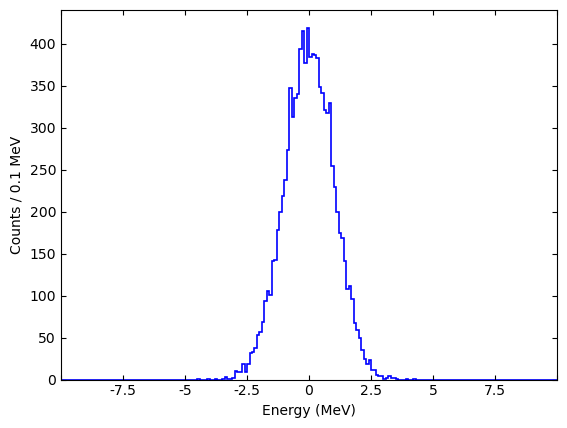

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter

data = np.random.normal(0, 1, 10000)

bin_width = 0.1
edges = np.arange(-10, 10 + bin_width / 2, bin_width)
counts, edges = np.histogram(data, bins=edges)
fig, ax = plt.subplots()
ax.stairs(counts,edges,color="blue",linewidth=1.2)

# 坐标轴范围
ax.set_xlim(edges[0], edges[-1])

# 横轴和纵轴标题居中
ax.set_xlabel("Energy (MeV)", loc="center")
ax.set_ylabel(f"Counts / {bin_width:g} MeV", loc="center")

# 四条边均显示向内的刻度线
ax.tick_params(axis="both",direction="in",top=True,right=True)

# 隐藏横轴两端的刻度标签，保留刻度线
ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: ""
        if np.isclose(x, edges[0]) or np.isclose(x, edges[-1])
        else f"{x:g}"
    )
)

# 纵轴科学计数法
if counts.max() >= 1000:
    ax.yaxis.set_major_locator(MultipleLocator(500))
    ax.ticklabel_format(axis="y",style="sci",scilimits=(3, 3),useMathText=True)

plt.show()

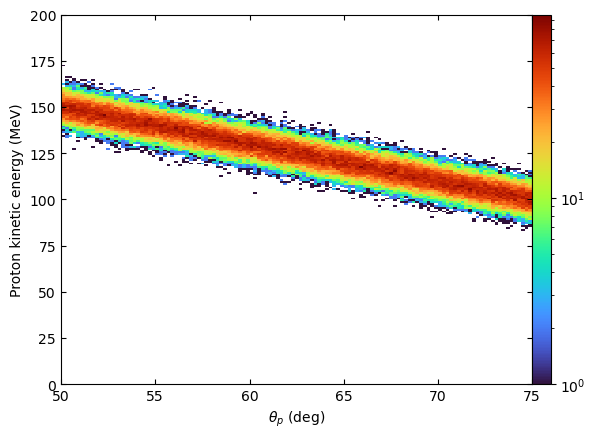

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# 1. 示例数据
theta = np.random.uniform(50, 75, 100000)
energy = 150 - 2 * (theta - 50) + np.random.normal(0, 5, 100000)
# 2. 定义分箱
angle_edges = np.linspace(50, 75, 126)
energy_edges = np.linspace(0, 200, 201)
# 3. 二维直方图统计
histogram, _, _ = np.histogram2d(theta, energy, bins=(angle_edges, energy_edges))

# 4. 绘制二维关联图
fig, ax = plt.subplots()

mesh = ax.pcolormesh(
    angle_edges, energy_edges, np.ma.masked_less_equal(histogram.T, 0),
    cmap="turbo",  # 常用：turbo、viridis、plasma、inferno、magma、cividis、jet
    norm=LogNorm(vmin=1, vmax=max(2, histogram.max())), shading="flat"
)

# 5. 坐标轴
ax.set_xlabel(r"$\theta_p$ (deg)", loc="center")
ax.set_ylabel("Proton kinetic energy (MeV)", loc="center")
ax.tick_params(direction="in", top=True, right=True)

# 6. 颜色条
fig.colorbar(mesh, ax=ax, pad=0.0, fraction=0.05)

plt.show()

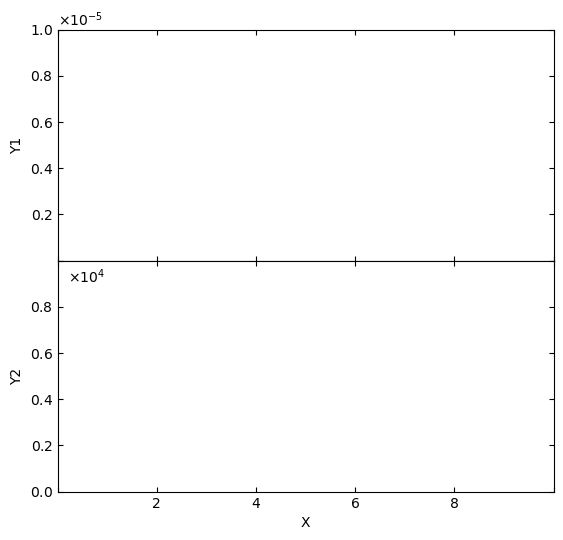

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# 1. 创建两行一列的图框
fig, axes = plt.subplots(2, 1, figsize=(6.4, 6.0), sharex=True, gridspec_kw={"hspace": 0})

# 2. 坐标轴范围
axes[0].set_ylim(0, 1e-5)
axes[1].set_ylim(0, 1e4)
axes[1].set_xlim(0, 10)

# 3. 设置刻度间隔
axes[0].yaxis.set_major_locator(MultipleLocator(2e-6))
axes[1].yaxis.set_major_locator(MultipleLocator(2000))
axes[1].xaxis.set_major_locator(MultipleLocator(2))

# 4. 纵轴科学计数法
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(-5, -5), useMathText=True)
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(4, 4), useMathText=True)

# 5. 坐标轴标签
axes[0].set_ylabel("Y1", loc="center")
axes[1].set_ylabel("Y2", loc="center")
axes[1].set_xlabel("X", loc="center")

# 6. 向内刻度线
for ax in axes:
    ax.tick_params(axis="both", direction="in", top=True, right=True)
    ax.grid(False)

# 7. 隐藏横轴两端和纵轴交界处的标签，保留刻度线
fig.canvas.draw()
# 隐藏下图默认的科学计数法标记
axes[1].yaxis.get_offset_text().set_visible(False)

# 在下图内部左上角显示 ×10⁴
axes[1].text(0.02, 0.97, r"$\times 10^{4}$", transform=axes[1].transAxes, ha="left", va="top")

for tick in axes[1].xaxis.get_major_ticks():
    if np.isclose(tick.get_loc(), 0) or np.isclose(tick.get_loc(), 10):
        tick.label1.set_visible(False)

for ax, boundary in [(axes[0], 0), (axes[1], 1e4)]:
    for tick in ax.yaxis.get_major_ticks():
        if np.isclose(tick.get_loc(), boundary, rtol=0, atol=1e-10):
            tick.label1.set_visible(False)

# 8. 两行无间隙
fig.subplots_adjust(hspace=0)

plt.show()

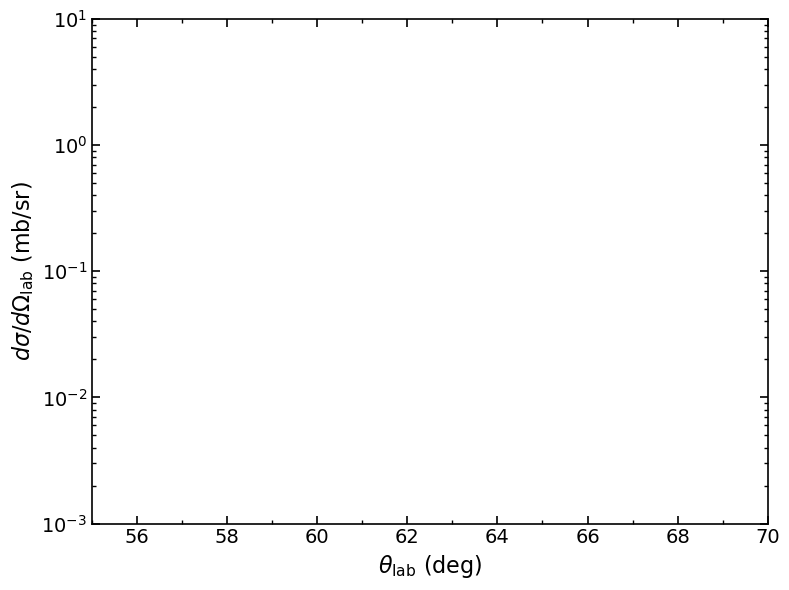

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext, AutoMinorLocator

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(55, 70)
ax.set_ylim(1e-3, 1e1)
ax.set_yscale("log")
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=range(2, 10)))
ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.tick_params(axis="both", which="major", direction="in", top=True, right=True, length=6, width=1.2, labelsize=14)
ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True, length=3, width=1.0)
for spine in ax.spines.values(): spine.set_linewidth(1.2)
ax.set_xlabel(r"$\theta_{\mathrm{lab}}$ (deg)", fontsize=16)
ax.set_ylabel(r"$d\sigma/d\Omega_{\mathrm{lab}}$ (mb/sr)", fontsize=16)
ax.grid(False)
plt.tight_layout()
plt.show()